# Day 22 · Projections — One field, four worldviews
### #30DayMapChallenge 2026 · ECMWF 9 km open data · Map by Emma Pidduck

The **same 500 hPa geopotential-height field** drawn on **four map projections**. The
synoptic pattern is identical in every panel — only the *canvas* changes. Watch the
**graticule** (the lat/lon grid) and the coastlines bend from one projection to the next:
that bending *is* the distortion every flat map of a round Earth has to make somewhere.

Self-contained: method, code, output, data licence and tools in one place, runnable on any
laptop with `pip`.

## Method

- Fetch one field — **500 hPa geopotential height** (`gh`), the classic mid-tropospheric
  chart that shows troughs and ridges — on the ECMWF **0.1° (~9 km)** open-data grid.
- Draw it **unchanged** on four projections, each with a property worth knowing:
  - **Plate Carrée** — plots lon/lat straight onto x/y. Simple, but *neither* equal-area
    *nor* conformal: areas and shapes both stretch toward the poles.
  - **Robinson** — a *compromise* pseudocylindrical projection; meridians curve, nothing is
    exactly preserved but nothing is badly wrong either.
  - **Lambert Conformal Conic** — *conformal*: preserves local angles and shapes. The
    standard choice for regional weather charts (and what Day 2 used).
  - **Lambert Azimuthal Equal-Area** — *equal-area*: a square kilometre is a square
    kilometre anywhere on the map. This is **EPSG:3035**, the EU's standard grid for
    statistics and comparison across Europe.
- Overlay the **graticule** in grey so the distortion is visible, not just asserted.

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

When you share a map made from this data, attribute it:
`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve IFS open data (the ECMWF API client) |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read & handle the GRIB (modern ECMWF stack) |
| `cartopy` | the four projections + coastlines, borders, graticule |
| [`cmcrameri`](https://www.fabiocrameri.ch/colourmaps/) | `batlow` — a perceptually-uniform, colourblind-safe ramp |

One gotcha baked in below: the Client **defaults to 0.25°** — pass `resol="0p1"` for the real
**0.1° (~9 km)** grid. Geopotential height comes in **gpm**; divide by 10 for **decametres
(dam)**, the usual unit on a 500 hPa chart (~500–590 dam).

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata earthkit-data cfgrib xarray cartopy cmcrameri matplotlib

In [2]:
import os, sys, io, contextlib
import numpy as np
import xarray as xr
import earthkit.data as ekd
from ecmwf.opendata import Client
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
import matplotlib.image as mpimg
from matplotlib.colors import to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cmcrameri import cm as cmc

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

@contextlib.contextmanager
def quiet():
    """Silence the open-data banner + download progress bars. Real errors still raise."""
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

### Configuration

`DATE = 0` pulls **today's** 00Z run, so re-running on **22 November 2026** produces that
day's chart with no edits. Pin a specific day with e.g. `DATE = "20261122"`.

In [3]:
DATE, TIME, STEP, LEVEL = 0, 0, 0, 500      # today 00Z, analysis step, 500 hPa
REGION = [-40, 45, 25, 72]                   # W, E, S, N — Europe + eastern Atlantic
GRIB   = "data/day22_z500.grib2"
AUTHOR = "Emma Pidduck"
BG, INK, MUT, GRID = "#ffffff", "#222222", "#6b6b6b", "#b9c0c8"

## Retrieve

One parameter on one pressure level
([gh = 156](https://codes.ecmwf.int/grib/param-db/156)). Downloaded to a file so re-runs are
reproducible and offline-friendly.

In [4]:
os.makedirs("data", exist_ok=True)
with quiet():
    if not os.path.exists(GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEP, stream="oper", type="fc",
            levtype="pl", levelist=LEVEL, param="gh", resol="0p1", target=GRIB)

## Reading & processing

Read the GRIB with **earthkit-data**, convert **gpm → dam**, and tidy the grid (longitudes
to −180…180 ascending, latitudes ascending) so the plotters behave.

In [5]:
ds = ekd.from_source("file", GRIB)
x  = ds.to_xarray().squeeze()
lon = x["longitude"].values.copy(); lat = x["latitude"].values.copy()
gh  = x["gh"].values / 10.0                       # gpm -> decametres (dam)

lon = ((lon + 180) % 360) - 180                   # wrap to -180..180
order = np.argsort(lon); lon, gh = lon[order], gh[:, order]
if lat[0] > lat[-1]:                              # make latitude ascending
    lat, gh = lat[::-1], gh[::-1]

mx = (lon >= REGION[0] - 6) & (lon <= REGION[1] + 6)   # subset (+margin) before plotting
my = (lat >= REGION[2] - 6) & (lat <= REGION[3] + 6)
lon, lat, gh = lon[mx], lat[my], gh[np.ix_(my, mx)]

VALID = str(xr.open_dataset(GRIB, engine="cfgrib")["valid_time"].values)[:16].replace("T", " ") + " UTC"
print(f"grid {gh.shape} at {abs(lat[1]-lat[0]):.2f} deg   valid {VALID}")
print(f"Z500 range: {gh.min():.0f}-{gh.max():.0f} dam")

Ignoring index file 'data/day22_z500.grib2.5b7b6.idx' incompatible with GRIB file


grid (590, 971) at 0.10 deg   valid 2026-10-28 00:00 UTC
Z500 range: 504-593 dam


### Colour — and why it is colourblind-safe

Height is a *sequential* quantity (low → high), so it wants a sequential ramp. We use
**`batlow`** from Fabio Crameri's scientific colour maps: perceptually uniform and
**monotonic in luminance**, which means it reads correctly for every form of colour-vision
deficiency *and* in greyscale. The cell below **validates** that monotonicity rather than
taking it on trust (`cividis` is an equally safe drop-in alternative).

In [6]:
CMAP = cmc.batlow
# CMAP = plt.get_cmap("cividis")   # by-construction-safe alternative

def luminance_monotonic(cmap, n=256):
    rgb = np.array([to_rgba(cmap(t))[:3] for t in np.linspace(0, 1, n)])
    lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]   # relative luminance
    d = np.diff(lum)
    return (d >= -1e-3).all() or (d <= 1e-3).all(), lum

ok, lum = luminance_monotonic(CMAP)
print(f"luminance-monotonic: {ok}   (luminance {lum[0]:.2f} -> {lum[-1]:.2f})")

luminance-monotonic: True   (luminance 0.10 -> 0.85)


## Plotting

Same `contourf` field + white isohypses in all four panels; only the `projection=` and the
title change. Each `set_extent` is given in Plate Carrée so every panel frames the *same*
geographic region — the projection then decides what that region looks like.

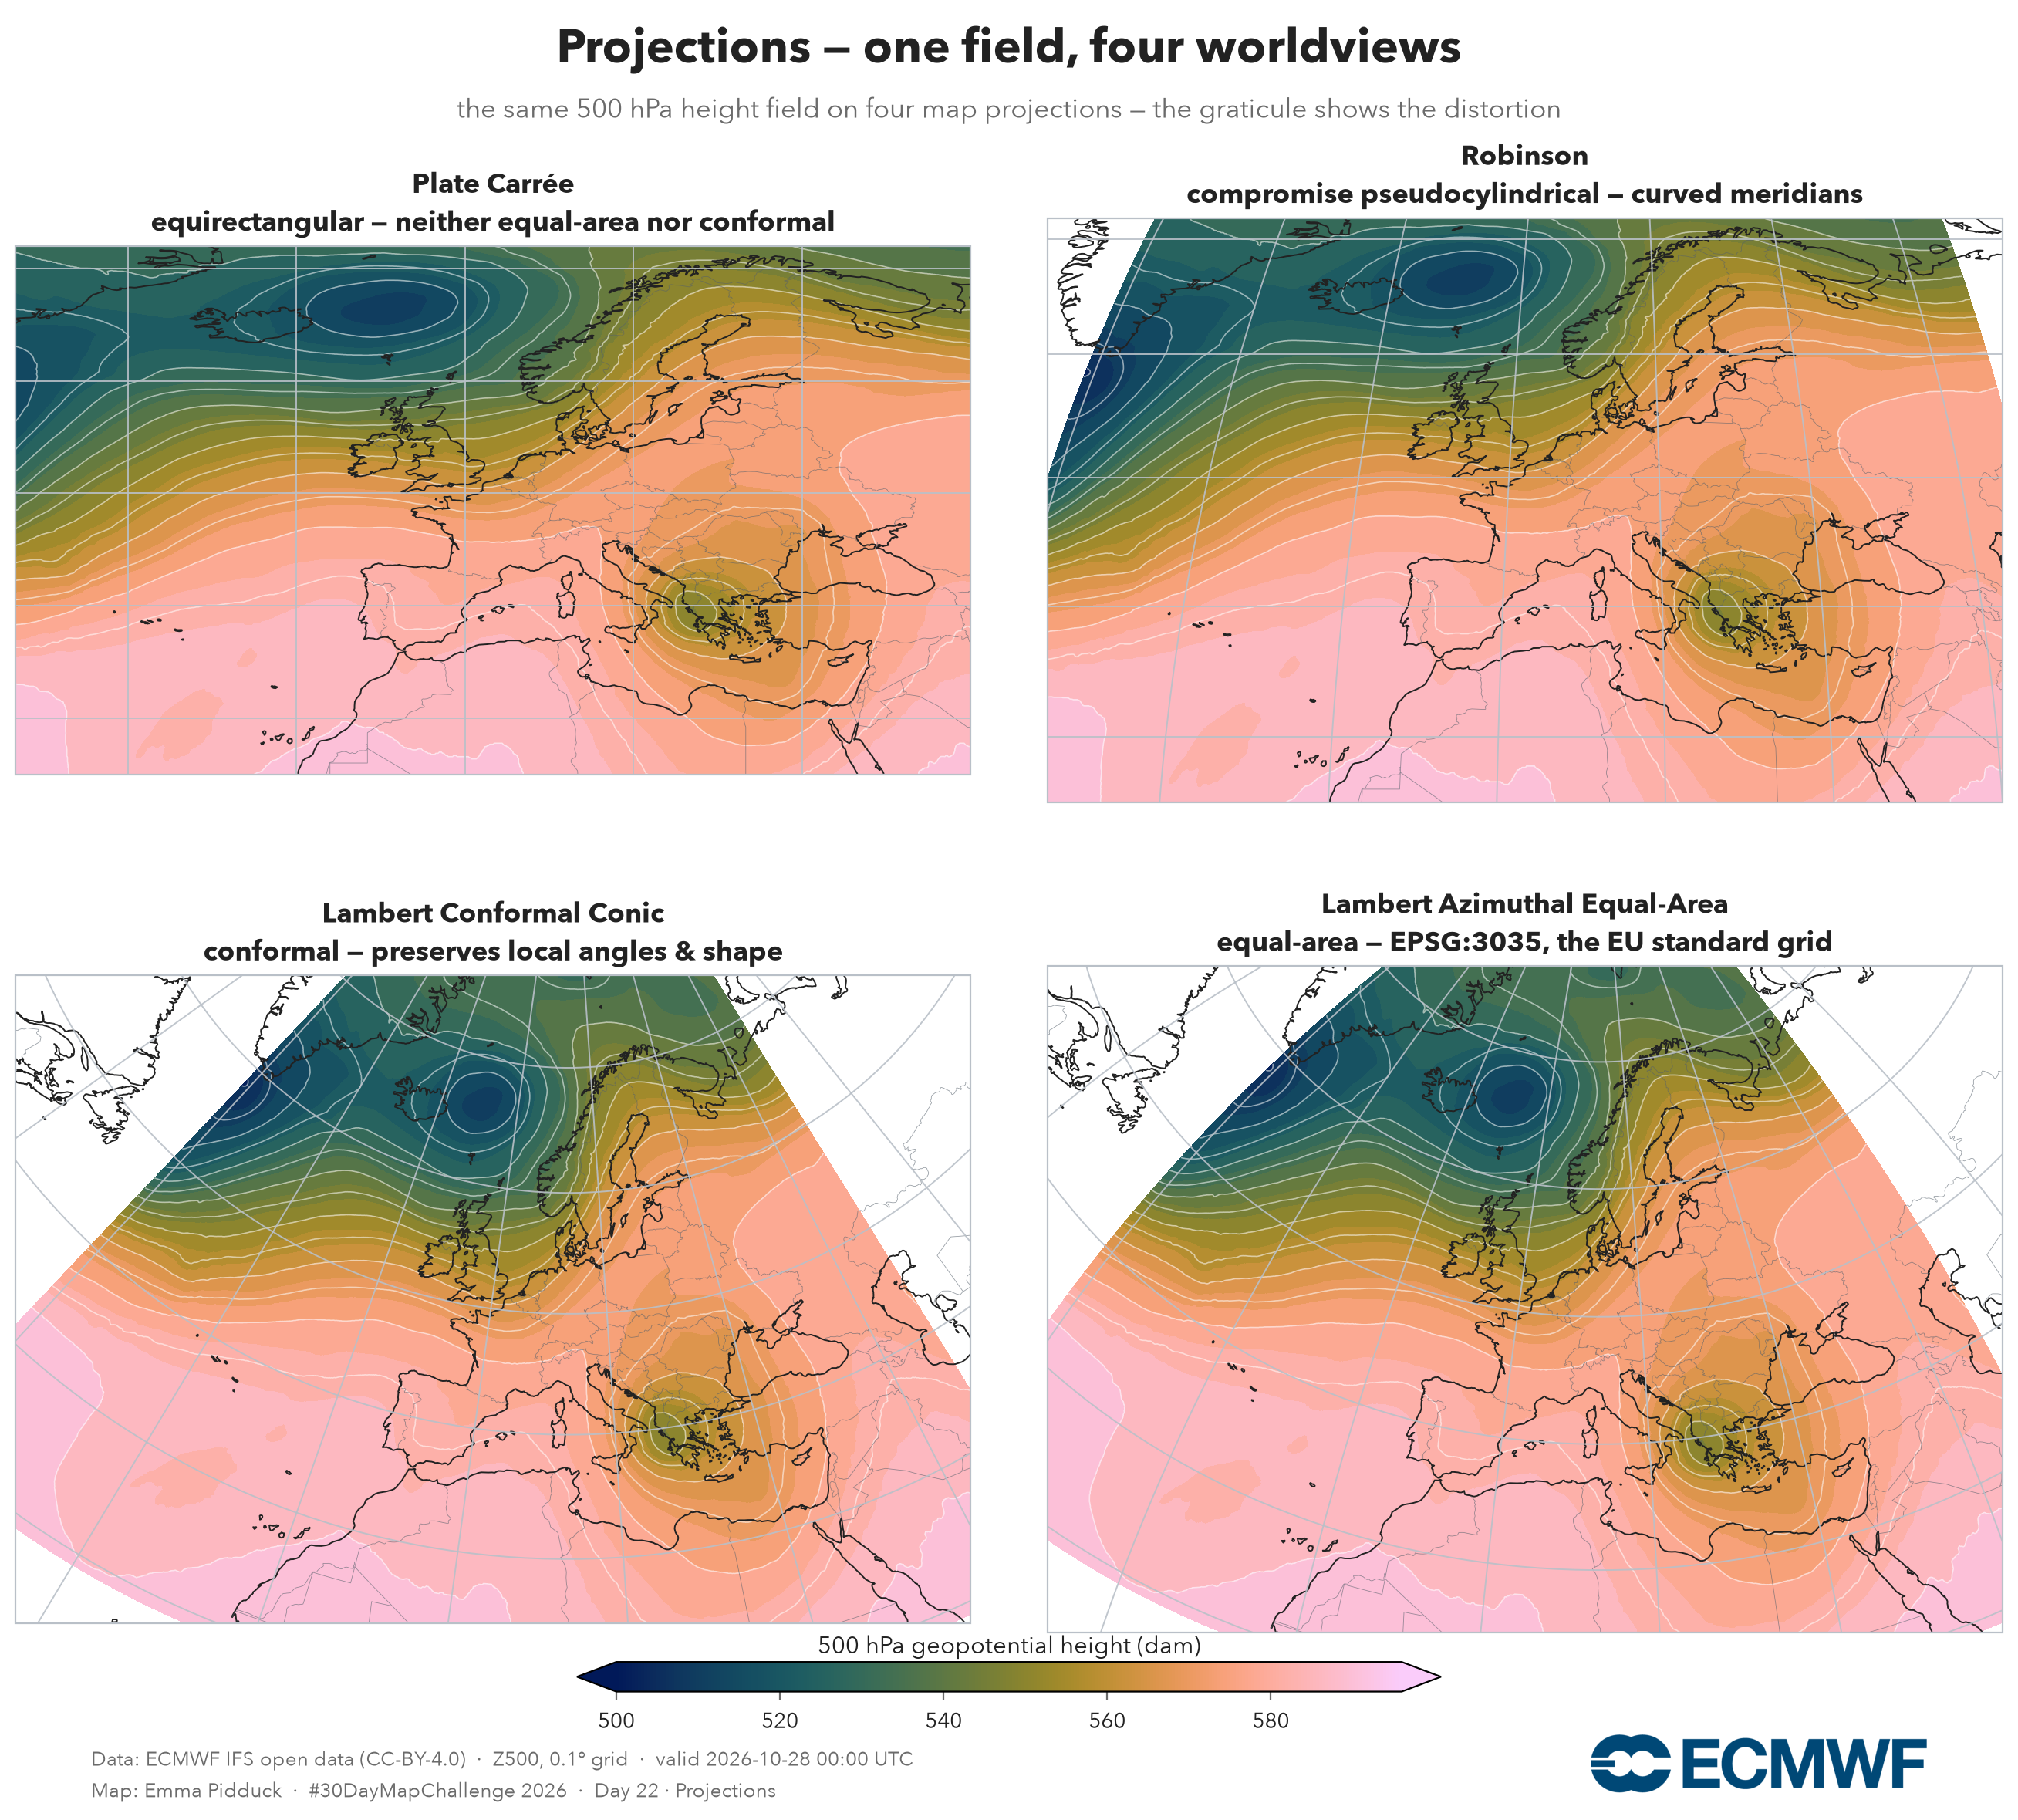

In [7]:
levels = np.arange(np.floor(gh.min()/4)*4, np.ceil(gh.max()/4)*4 + 4, 4)   # 4 dam fill steps
clines = np.arange(480, 600, 6)                                            # 6 dam isohypses
vmin, vmax = levels[0], levels[-1]

PROJ = [
    ("Plate Carrée",                  ccrs.PlateCarree(),
     "equirectangular — neither equal-area nor conformal"),
    ("Robinson",                      ccrs.Robinson(central_longitude=10),
     "compromise pseudocylindrical — curved meridians"),
    ("Lambert Conformal Conic",       ccrs.LambertConformal(central_longitude=10,
         central_latitude=52, standard_parallels=(35, 65)),
     "conformal — preserves local angles & shape"),
    ("Lambert Azimuthal Equal-Area",  ccrs.LambertAzimuthalEqualArea(central_longitude=10,
         central_latitude=52),
     "equal-area — EPSG:3035, the EU standard grid"),
]
tp = dict(transform=ccrs.PlateCarree())

fig = plt.figure(figsize=(14, 12), dpi=200); fig.patch.set_facecolor(BG)
mappable = None
for i, (name, proj, prop) in enumerate(PROJ):
    ax = fig.add_subplot(2, 2, i + 1, projection=proj)
    ax.set_facecolor(BG); ax.set_extent(REGION, crs=ccrs.PlateCarree())
    try: ax.spines["geo"].set_edgecolor(GRID); ax.spines["geo"].set_linewidth(0.8)
    except Exception: pass
    mappable = ax.contourf(lon, lat, gh, levels=levels, cmap=CMAP, vmin=vmin, vmax=vmax,
                           extend="both", zorder=0, **tp)
    ax.contour(lon, lat, gh, levels=clines, colors="#ffffff", linewidths=0.6,
               alpha=0.55, zorder=1, **tp)
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor=INK, linewidth=0.7, zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#55606b", linewidth=0.3,
                   alpha=0.6, zorder=2)
    ax.gridlines(draw_labels=False, xlocs=range(-60, 61, 15), ylocs=range(10, 81, 10),
                 color=GRID, linewidth=0.7, alpha=0.9, zorder=3)
    ax.set_title(f"{name}\n{prop}", color=INK, fontsize=13, pad=7, fontweight="bold")

# shared colourbar — label above the bar, clear of the footer
cax = fig.add_axes([0.30, 0.085, 0.40, 0.016])
cb = fig.colorbar(mcm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap=CMAP),
                  cax=cax, orientation="horizontal", extend="both")
cb.set_label("500 hPa geopotential height (dam)", color=INK, fontsize=11)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)

fig.text(0.5, 0.965, "Projections — one field, four worldviews",
         ha="center", color=INK, fontsize=22, fontweight="bold")
fig.text(0.5, 0.935, "the same 500 hPa height field on four map projections — the graticule shows the distortion",
         ha="center", color=MUT, fontsize=12.5)
fig.text(0.075, 0.045, f"Data: ECMWF IFS open data (CC-BY-4.0)  ·  Z500, 0.1° grid  ·  valid {VALID}",
         color=MUT, fontsize=9.5)
fig.text(0.075, 0.028, f"Map: {AUTHOR}  ·  #30DayMapChallenge 2026  ·  Day 22 · Projections",
         color=MUT, fontsize=9.5)

logo = "assets/ECMWF_Core_Logo_RGB.png"
if os.path.exists(logo):
    img = mpimg.imread(logo); ar = img.shape[1] / img.shape[0]
    h = 0.032; w = h * ar * (fig.get_figheight() / fig.get_figwidth())
    la = fig.add_axes([0.925 - w, 0.03, w, h]); la.imshow(img); la.axis("off")

fig.subplots_adjust(left=0.04, right=0.96, top=0.91, bottom=0.11, wspace=0.08, hspace=0.14)
fig.savefig("day22_projections.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Bonus — go global

The interrupted, elliptical and azimuthal projections below only *sing* on a whole-globe
field — on a regional crop they just look like a cropped rectangle. So here is **today's
global 2 m temperature** drawn on six of the weirdest: the orange-peel **Interrupted Goode**,
**Equal Earth**, **Mollweide**, **Eckert IV** (flat poles), the **Orthographic** globe-from-space,
and the **Geostationary** disc — literally the Meteosat view from 0°.

At planet scale the 9 km detail is invisible, so here the *coarse* 0.25° grid is the right
choice (the Day 2/20 `resol="0p1"` gotcha, inverted).

### Is the palette colourblind-safe? Validate, don't assume.

Temperature is a *diverging* quantity (cold ↔ warm about freezing), so the luminance-monotonic
test used for Z500 doesn't apply — a diverging ramp is meant to be dark–light–dark. The right
check is to **simulate colour-vision deficiency** and confirm the two arms stay distinct. We
use **`vik`** (Crameri) and verify it with a self-contained **Viénot–Brettel–Mollon (1999)**
dichromat simulation — no extra dependency. The swatch shows cold→warm surviving both
deuteranopia and protanopia.

vik under deuteranopia: cold–warm colour distance 0.43   (distinguishable if > 0.3)
vik under protanopia  : cold–warm colour distance 0.38   (distinguishable if > 0.3)


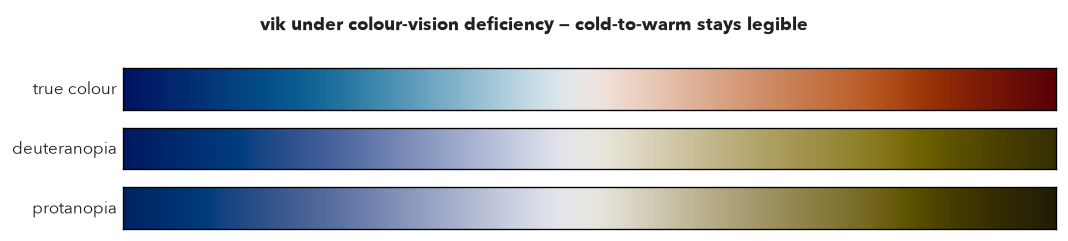

In [8]:
CMAP_G = cmc.vik                     # diverging, 0 °C at the neutral centre

# Viénot–Brettel–Mollon (1999) dichromat simulation, applied in linear RGB
_M = {"deuteranopia": np.array([[ 0.367322, 0.860646, -0.227968],
                                [ 0.280085, 0.672501,  0.047413],
                                [-0.011820, 0.042940,  0.968881]]),
      "protanopia":   np.array([[ 0.152286, 1.052583, -0.204868],
                                [ 0.114503, 0.786281,  0.099216],
                                [-0.003882,-0.048116,  1.051998]])}
_lin  = lambda c: np.where(c <= 0.04045, c/12.92, ((c+0.055)/1.055)**2.4)
_srgb = lambda c: np.where(c <= 0.0031308, 12.92*c, 1.055*c**(1/2.4)-0.055)
def simulate_cvd(rgb, kind):
    return _srgb(np.clip(_lin(np.clip(rgb, 0, 1)) @ _M[kind].T, 0, 1))

ramp = np.array([to_rgba(CMAP_G(t))[:3] for t in np.linspace(0, 1, 256)])
for kind in ("deuteranopia", "protanopia"):
    d = np.linalg.norm(simulate_cvd(ramp, kind)[0] - simulate_cvd(ramp, kind)[-1])
    print(f"vik under {kind:12s}: cold–warm colour distance {d:.2f}   (distinguishable if > 0.3)")

sw, axes = plt.subplots(3, 1, figsize=(9, 2.0), dpi=120)
for a, (lab, k) in zip(axes, [("true colour", None), ("deuteranopia", "deuteranopia"),
                              ("protanopia", "protanopia")]):
    strip = ramp if k is None else simulate_cvd(ramp, k)
    a.imshow(strip[None, :, :], aspect="auto"); a.set_xticks([]); a.set_yticks([])
    a.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=10, color=INK)
sw.suptitle("vik under colour-vision deficiency — cold-to-warm stays legible",
            fontsize=11, fontweight="bold", color=INK)
sw.tight_layout(); plt.show()

global grid (721, 1441)  T -56..36 °C  valid 2026-10-28 00:00 UTC


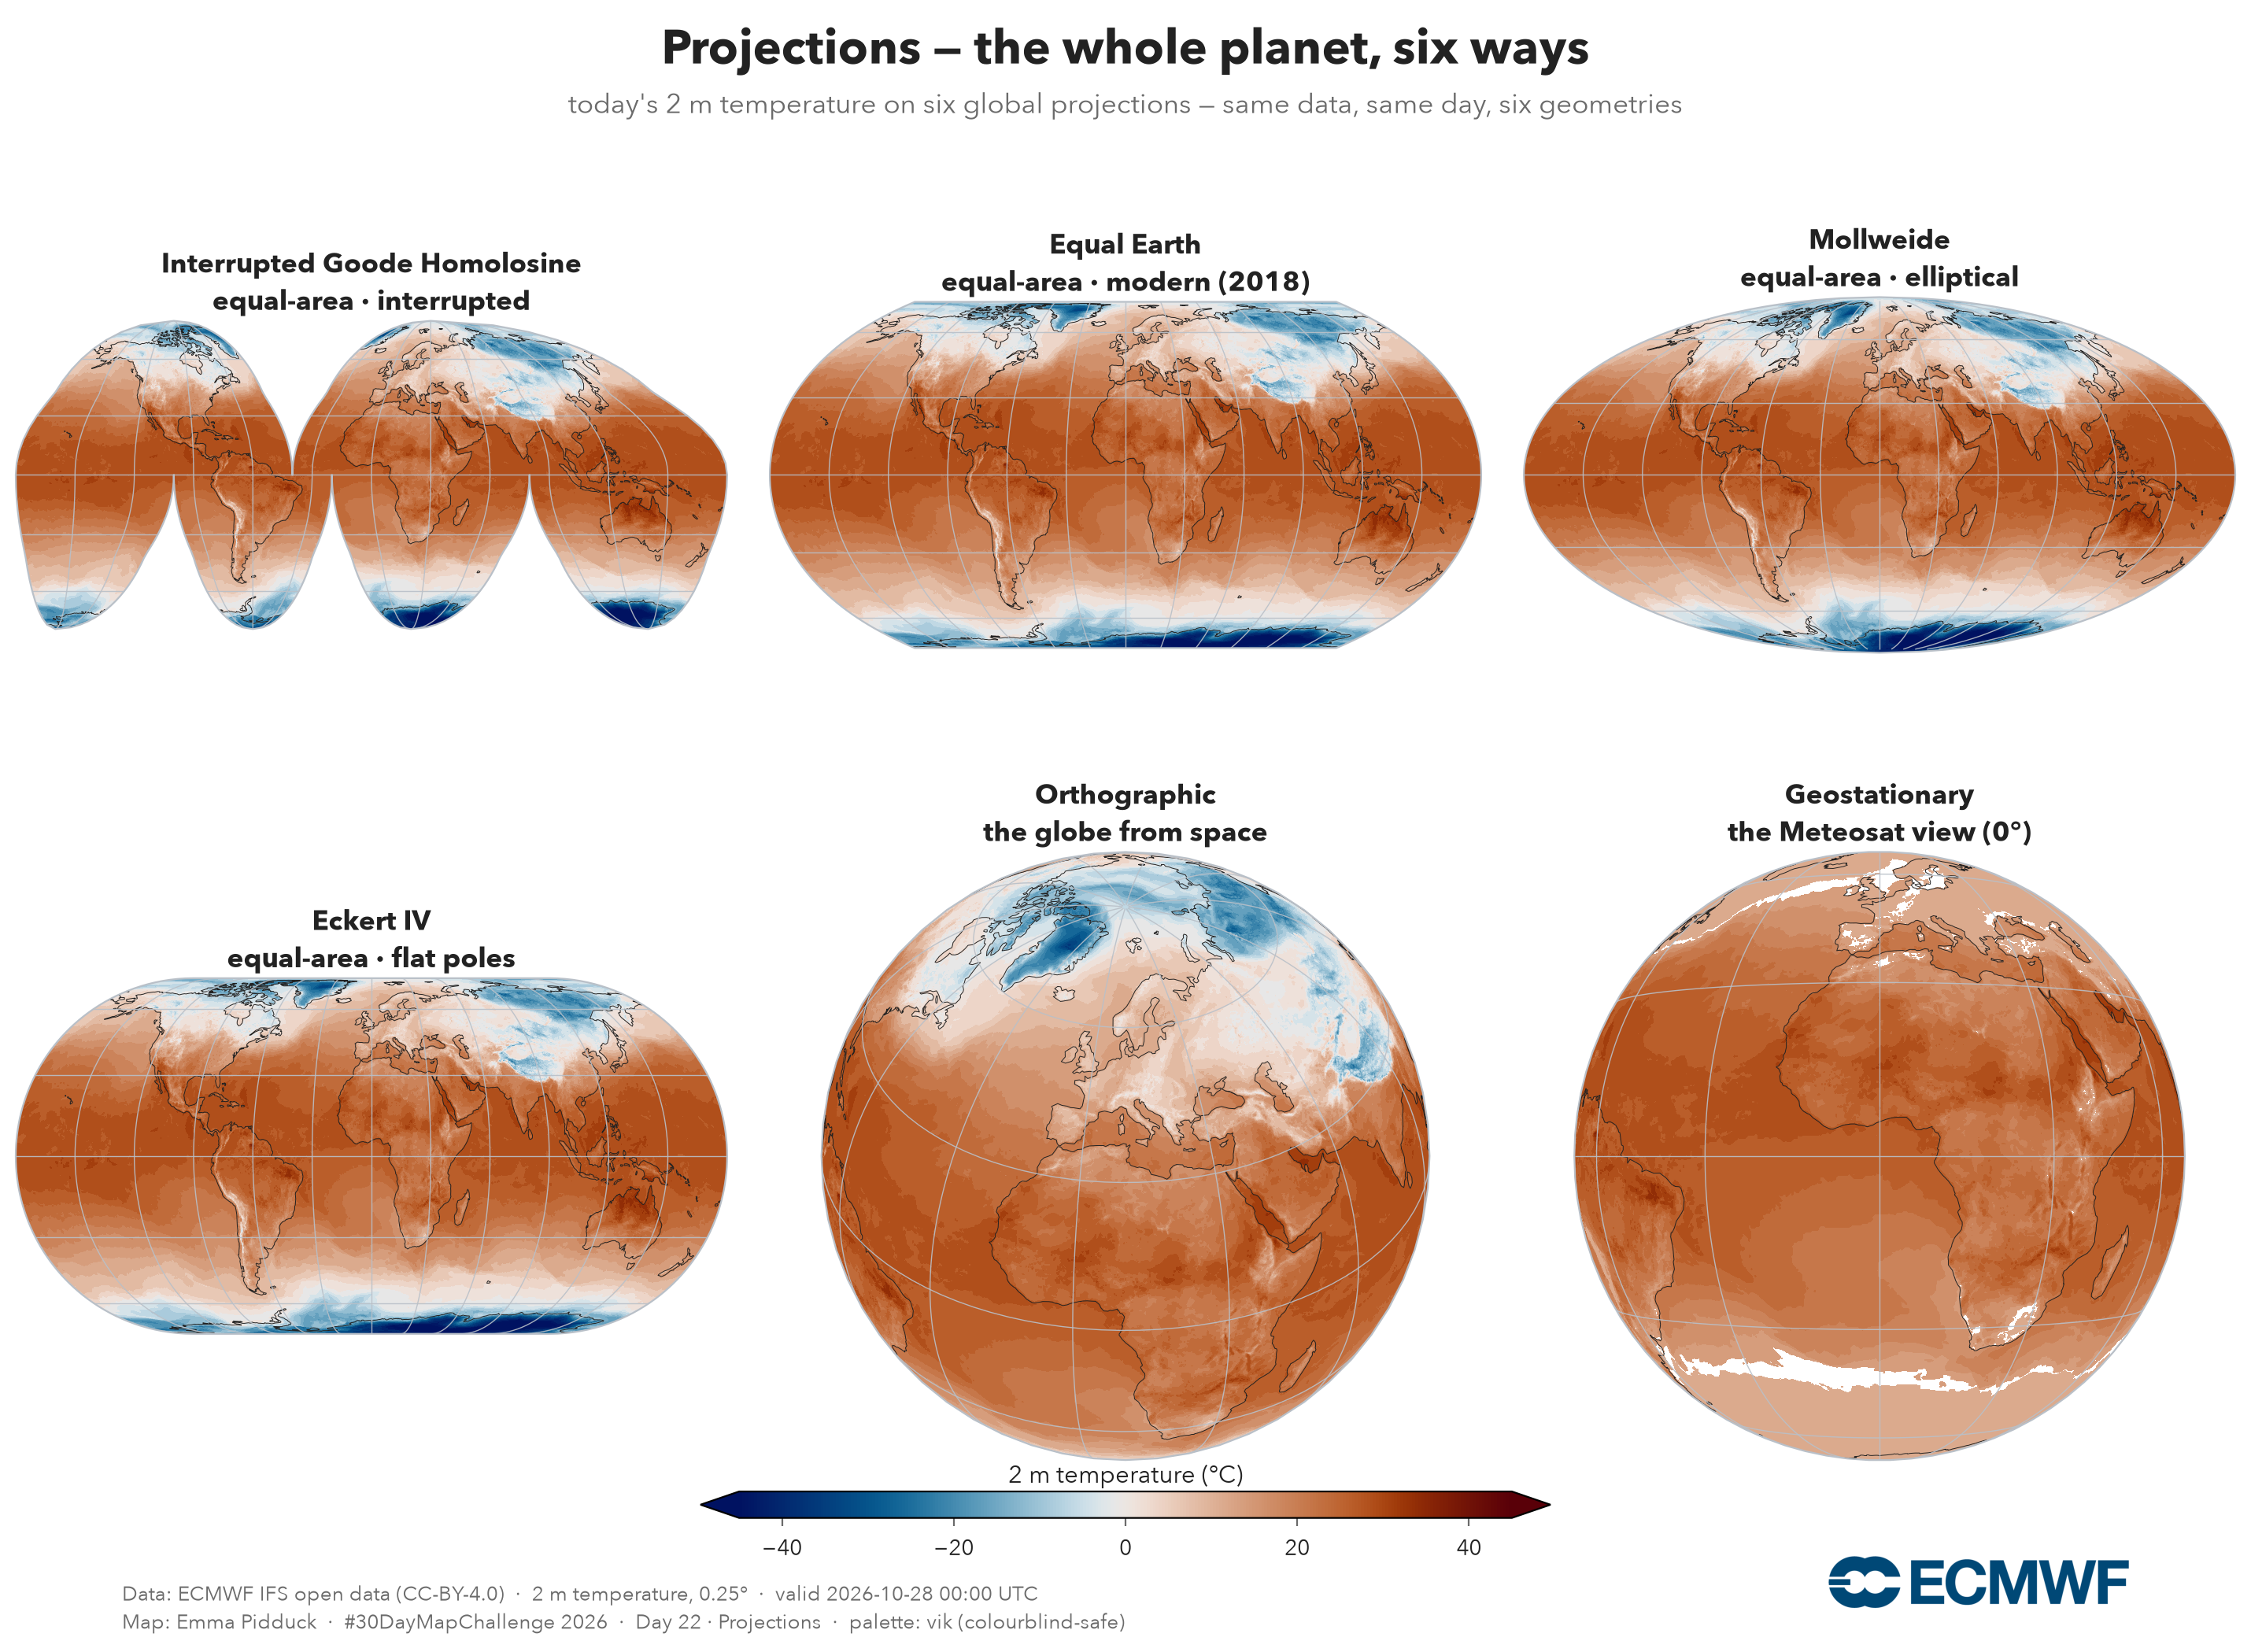

In [9]:
from cartopy.util import add_cyclic_point

GRIB_G = "data/day22_2t_global.grib2"
with quiet():
    if not os.path.exists(GRIB_G):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEP, stream="oper", type="fc",
            levtype="sfc", param="2t", target=GRIB_G)          # default 0.25° grid
    xg = ekd.from_source("file", GRIB_G).to_xarray().squeeze()
glon = xg["longitude"].values; glat = xg["latitude"].values
t2m  = xg["2t"].values - 273.15                                # K -> °C
o = np.argsort(glon); glon, t2m = glon[o], t2m[:, o]
if glat[0] > glat[-1]: glat, t2m = glat[::-1], t2m[::-1]
t2m, glonc = add_cyclic_point(t2m, coord=glon)                 # seamless across the dateline
VALID_G = str(xr.open_dataset(GRIB_G, engine="cfgrib")["valid_time"].values)[:16].replace("T", " ") + " UTC"
print(f"global grid {t2m.shape}  T {t2m.min():.0f}..{t2m.max():.0f} °C  valid {VALID_G}")

glevels = np.linspace(-45, 45, 37)                             # 2.5 °C steps; 0 °C = vik's centre
GPROJ = [
    ("Interrupted Goode Homolosine", ccrs.InterruptedGoodeHomolosine(),  "equal-area · interrupted"),
    ("Equal Earth",       ccrs.EqualEarth(central_longitude=0),          "equal-area · modern (2018)"),
    ("Mollweide",         ccrs.Mollweide(central_longitude=0),           "equal-area · elliptical"),
    ("Eckert IV",         ccrs.EckertIV(central_longitude=0),            "equal-area · flat poles"),
    ("Orthographic",      ccrs.Orthographic(central_longitude=10, central_latitude=35), "the globe from space"),
    ("Geostationary",     ccrs.Geostationary(central_longitude=0),       "the Meteosat view (0°)"),
]

figG = plt.figure(figsize=(15, 10.5), dpi=200); figG.patch.set_facecolor(BG)
for i, (name, proj, prop) in enumerate(GPROJ):
    ax = figG.add_subplot(2, 3, i + 1, projection=proj)
    ax.set_facecolor(BG); ax.set_global()
    ax.contourf(glonc, glat, t2m, levels=glevels, cmap=CMAP_G, extend="both", zorder=0, **tp)
    ax.add_feature(cfeature.COASTLINE.with_scale("110m"), edgecolor=INK, linewidth=0.35, zorder=2)
    ax.gridlines(color=GRID, linewidth=0.5, alpha=0.9, zorder=3,
                 xlocs=range(-150, 181, 30), ylocs=range(-60, 61, 30))
    try: ax.spines["geo"].set_edgecolor(GRID); ax.spines["geo"].set_linewidth(0.8)
    except Exception: pass
    ax.set_title(f"{name}\n{prop}", color=INK, fontsize=12.5, pad=5, fontweight="bold")

caxG = figG.add_axes([0.32, 0.085, 0.36, 0.016])
cbG = figG.colorbar(mcm.ScalarMappable(norm=plt.Normalize(-45, 45), cmap=CMAP_G),
                    cax=caxG, orientation="horizontal", extend="both")
cbG.set_label("2 m temperature (°C)", color=INK, fontsize=11)
cbG.set_ticks([-40, -20, 0, 20, 40]); cbG.ax.xaxis.set_label_position("top")
cbG.ax.xaxis.set_tick_params(color=MUT); plt.setp(plt.getp(cbG.ax, "xticklabels"), color=INK)

figG.text(0.5, 0.965, "Projections — the whole planet, six ways", ha="center", color=INK,
          fontsize=22, fontweight="bold")
figG.text(0.5, 0.935, "today's 2 m temperature on six global projections — same data, same day, six geometries",
          ha="center", color=MUT, fontsize=12.5)
figG.text(0.075, 0.035, f"Data: ECMWF IFS open data (CC-BY-4.0)  ·  2 m temperature, 0.25°  ·  valid {VALID_G}",
          color=MUT, fontsize=9.5)
figG.text(0.075, 0.018, "Map: Emma Pidduck  ·  #30DayMapChallenge 2026  ·  Day 22 · Projections  ·  palette: vik (colourblind-safe)",
          color=MUT, fontsize=9.5)
if os.path.exists(logo):
    img = mpimg.imread(logo); ar = img.shape[1] / img.shape[0]
    hh = 0.032; ww = hh * ar * (figG.get_figheight() / figG.get_figwidth())
    laG = figG.add_axes([0.925 - ww, 0.03, ww, hh]); laG.imshow(img); laG.axis("off")
figG.subplots_adjust(left=0.03, right=0.97, top=0.90, bottom=0.12, wspace=0.06, hspace=0.12)
figG.savefig("day22_projections_global.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Note

Every flat map trades something away — Plate Carrée and Robinson keep neither area nor
shape exactly; Lambert Conformal keeps **shape** (angles); Lambert Azimuthal Equal-Area
keeps **area**. There is no projection that keeps both: that is
[Gauss's *Theorema Egregium*](https://en.wikipedia.org/wiki/Theorema_Egregium) — you cannot
flatten a sphere without stretching it somewhere. Choose the projection for the job:
**conformal** for navigation and weather charts, **equal-area** (EPSG:3035) when you compare
quantities across Europe.

**Saved:** `day22_projections.png` (the regional 2×2) and `day22_projections_global.png`
(the global gallery) — both ready to post.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and MeteoSwiss) open data.
Day 2 is Lines — the jet stream; Day 20 is Hexagons — resolution made visible.*